# PW retrieval with `apda` — how to

1. Load the LUT
2. Build a **scene**: an `xr.Dataset` with `rho_toa` + geometry — an image or a set of simulations
3. `apda.retrieve(lut, scene, band)`
4. Single-geometry building blocks: `APDALUT.collapse` → `APDA.fit` → `APDA.retrieve`
5. Optional: empirical path-reflectance tuning (Eqs. 16–17)

Data paths come from `APDA_LUT_PATH` / `APDA_TOA_PATH` (defaults: the HYPS files on `/mnt/ceph`).

In [1]:
import os

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from core import log
log.set_lvl(log.lvl.WARNING)  # apda logs every fit / iteration at debug level
%matplotlib inline

from apda import APDA, APDALUT, retrieve, scene_geometry, select_channels

LUT_PATH = os.environ.get("APDA_LUT_PATH", "/mnt/ceph/proj/hyperspectral/artdeco_corathyp_lut_ft4/lut_get_h2o.nc")
TOA_PATH = os.environ.get("APDA_TOA_PATH", "/mnt/ceph/proj/hyperspectral/hygeos_data_corathyp_sub_FT4.nc")

## 1. LUT

Operational MODTRAN-style LUT: `rho_atm`, `rho_toa` over `WV` (g/cm²), `wavelength` (µm), `sza`, `vza`, `raa` (deg, [0, 180]), `aot`, `rho`.

In [2]:
lut = APDALUT(LUT_PATH)
lut.validate()
lut.ds[["rho_atm", "rho_toa"]]

<xarray.Dataset> Size: 19MB
Dimensions:     (aot: 3, sza: 3, WV: 13, vza: 2, raa: 46, wavelength: 45, rho: 4)
Coordinates:
  * aot         (aot) float64 24B 0.05 0.15 0.4
  * sza         (sza) float64 24B 22.0 44.0 76.0
  * WV          (WV) float64 104B 0.09 0.28 0.56 0.91 1.3 ... 3.93 4.57 5.26 6.0
  * vza         (vza) float64 16B 30.0 0.0
  * raa         (raa) float64 368B 0.0 4.0 8.0 12.0 ... 168.0 172.0 176.0 180.0
  * wavelength  (wavelength) float64 360B 0.85 0.86 0.87 0.88 ... 1.27 1.28 1.29
    bandlist    (wavelength) int64 360B ...
  * rho         (rho) float64 32B 0.0 0.3 0.5 1.0
Data variables:
    rho_atm     (aot, sza, WV, vza, raa, wavelength) float64 4MB ...
    rho_toa     (aot, sza, WV, rho, vza, raa, wavelength) float64 16MB ...
Attributes:
    computing_time:  88.13113975524902
    n_stream:        8
    atmos_prof:      atm_afgl_us62.dat

## 2. Scene

| variable | dims | units |
|---|---|---|
| `rho_toa` | `(..., wavelength)` | reflectance, wavelength in µm |
| `sza`, `vza` | scalar or subset of the spatial dims | deg |
| `raa`, or `saa` + `vaa` | same | deg, any range |
| `aot` | same | — |
| `wv_init`, `valid` | same, optional | g/cm², bool |

The HYPS simulations as a scene — spatial dims `(simulation_config, spectrum_type)`, geometry over `simulation_config`:

In [3]:
hyps = xr.open_dataset(TOA_PATH)
scene = xr.Dataset({
    "rho_toa": hyps["toa_reflectance"].rename(toa_lambda0="wavelength"),  # (config, surface, wavelength)
    "sza": hyps["modtran_sun_zenith"],                                   # (config,) — shared by the surfaces
    "vza": hyps["modtran_view_zenith"],
    "saa": hyps["modtran_sun_azimuth"],
    "vaa": hyps["modtran_view_azimuth"],
    "aot": hyps["modtran_aot"],
}).reset_coords(drop=True)
wv_true = hyps["modtran_water_vapor"].values * 0.1  # truth per config, kg/m² → g/cm² (simulations only)
scene

<xarray.Dataset> Size: 3MB
Dimensions:        (wavelength: 184, spectrum_type: 10, simulation_config: 216)
Coordinates:
  * wavelength     (wavelength) float64 1kB 0.4 0.41 0.42 0.43 ... 2.38 2.39 2.4
  * spectrum_type  (spectrum_type) |S41 410B b'kaolinite' ... b'Desert_Algeri...
Dimensions without coordinates: simulation_config
Data variables:
    rho_toa        (simulation_config, spectrum_type, wavelength) float64 3MB ...
    sza            (simulation_config) float64 2kB ...
    vza            (simulation_config) float64 2kB ...
    saa            (simulation_config) float64 2kB ...
    vaa            (simulation_config) float64 2kB ...
    aot            (simulation_config) float64 2kB ...

An image is the same thing with `(y, x)` dims. A toy example, scalar geometry:

In [4]:
image = xr.Dataset({
    "rho_toa": scene["rho_toa"].isel(simulation_config=slice(0, 12)).rename(simulation_config="y", spectrum_type="x"),
    "sza": 22.0, "vza": 0.0, "saa": 135.0, "vaa": 67.0, "aot": 0.05,
})
retrieve(lut, image, "910", rho=0.5)

<xarray.DataArray 'water_vapour_column' (y: 12, x: 10)> Size: 960B
array([[0.90345245, 0.74513967, 0.82970367, 0.83207882, 0.88020652,
        0.90145429, 0.80050956, 0.95386264, 0.85850973, 0.9611393 ],
       [0.98809715, 0.82167221, 0.90982911, 0.91394136, 0.9634114 ,
        0.981307  , 0.87895969, 1.03941467, 0.93929437, 1.04731963],
       [1.0327576 , 0.8654021 , 0.95535747, 0.95710245, 1.00908816,
        1.03051455, 0.92399677, 1.08747229, 0.98583511, 1.0947121 ],
       [3.234022  , 2.84327566, 2.9904077 , 3.11514447, 3.13046496,
        3.07633602, 2.92062672, 3.23256549, 3.02407561, 3.26217287],
       [3.52271434, 3.10420358, 3.25926519, 3.4001831 , 3.41138133,
        3.32447478, 3.18357924, 3.51287047, 3.2906426 , 3.5470661 ],
       [3.25024125, 2.8300614 , 2.98241497, 3.12935061, 3.13398145,
        3.03083567, 2.90847981, 3.22586562, 3.01085032, 3.26540228],
       [3.54374356, 3.09934684, 3.2586192 , 3.41915253, 3.42062843,
        3.29635127, 3.17952477, 3.51381009, 3.28593328, 3.55631259],
       [3.68179769, 3.26203127, 3.41902745, 3.55789831, 3.57244187,
        3.48742164, 3.34193326, 3.67769276, 3.4512793 , 3.71031897],
       [3.97076416, 3.52999619, 3.69258294, 3.84376005, 3.85530498,
        3.74879683, 3.61100918, 3.96093254, 3.72345502, 3.99663379],
       [3.62878206, 3.23909825, 3.39453362, 3.50563681, 3.53697291,
        3.47040298, 3.32030384, 3.64874807, 3.42946048, 3.67482425],
       [3.91426541, 3.50361955, 3.66516473, 3.78788567, 3.81684575,
        3.72794429, 3.58633286, 3.9291338 , 3.69873602, 3.95826291],
       [3.69360894, 3.26681881, 3.42427361, 3.56914416, 3.57996017,
        3.49233354, 3.34671021, 3.68373756, 3.45615474, 3.71799471]])
Coordinates:
  * x        (x) |S41 410B b'kaolinite' ... b'Desert_Algerie4_ONERA'
Dimensions without coordinates: y
Attributes:
    units:             g/cm^2
    description:       Columnar H2O retrieved by APDA (2 iterations)
    band:              910
    n_geometry_nodes:  1

## 3. Retrieve

The LUT is linearly interpolated at each pixel's geometry (rounded to `apda.scene.GEOMETRY_STEP`); one model is fitted per distinct geometry. Geometry outside the LUT range is clamped with a warning.

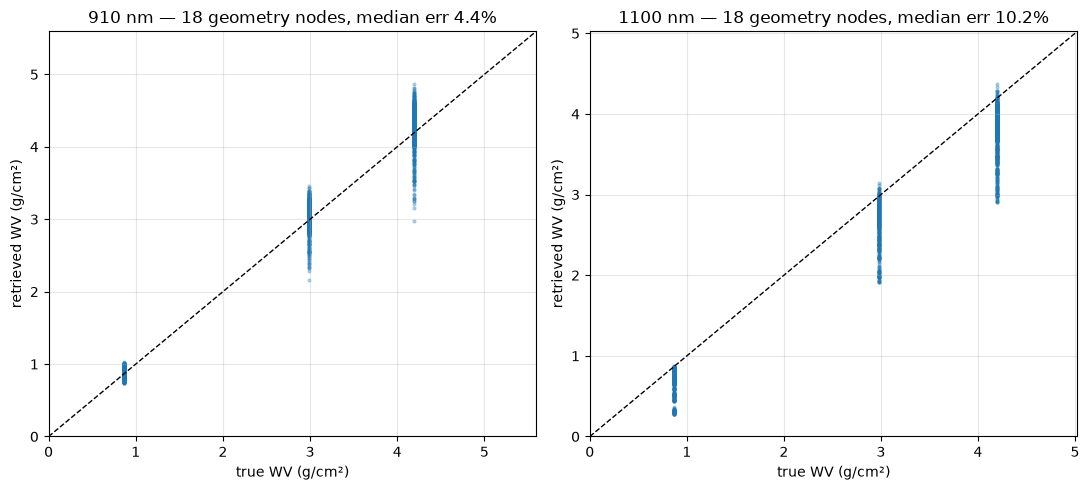

In [5]:
wv = xr.DataArray(wv_true, dims="simulation_config")
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, band in zip(axes, ("910", "1100")):
    pw = retrieve(lut, scene, band, rho=0.5)
    t, est = xr.broadcast(wv, pw)
    med = float((abs(est - t) / t).median())
    ax.scatter(t, est, s=4, alpha=0.3)
    lim = [0, 1.15 * float(pw.max())]
    ax.plot(lim, lim, "k--", lw=1)
    ax.set(xlim=lim, ylim=lim, xlabel="true WV (g/cm²)", ylabel="retrieved WV (g/cm²)",
           title=f"{band} nm — {pw.attrs['n_geometry_nodes']} geometry nodes, median err {med:.1%}")
    ax.grid(alpha=0.3)
plt.tight_layout()

## 4. Single geometry, step by step

Collapse the LUT to one geometry and one surface-reflectance node, fit `R = exp(-(c + a·PW^b))`, then retrieve.

In [6]:
geometry = scene_geometry(scene)
g0 = {k: float(v[0]) for k, v in geometry.items()}
same = np.all([np.isclose(geometry[k].values, g0[k]) for k in g0], axis=0)
toa = scene["rho_toa"].isel(simulation_config=np.flatnonzero(same))
print(g0, toa.shape)

channels = select_channels("910")
collapsed = lut.collapse(**g0, channels=channels, rho=0.5)
retriever = APDA(collapsed, channels)
print("fit:", retriever.fit())
print("ratio (Eq. 6):", retriever.compute_ratio(toa, pw=2.0).values[0].round(4))
pw = retriever.retrieve(toa, pw_initial=2.0, n_iter=2)
truth = wv_true[np.flatnonzero(same)][:, None]
print(f"median |rel err| = {np.median(np.abs(pw.values - truth) / truth):.2%}")

{'sza': 22.0, 'vza': 0.0, 'raa': 68.0, 'aot': 0.05} (12, 10, 184)
fit: {'a': 0.24114744691360582, 'b': 0.5465853738706112, 'c': -0.03156285989860418}
ratio (Eq. 6): [0.8218 0.8418 0.831  0.8301 0.8247 0.824  0.8347 0.8166 0.8277 0.8155]
median |rel err| = 3.91%


## 5. Optional: path-reflectance tuning

Find α minimising σ(PW) over a flat, spectrally diverse subset (Eqs. 16–17), then retrieve with it. Here: one config, all surfaces (same true WV).

In [7]:
sub = toa.isel(simulation_config=[0])
alpha = retriever.optimize_path_radiance(sub)
print("alpha =", alpha)
print("std without / with alpha:", float(retriever.retrieve(sub).std()),
      float(retriever.retrieve(sub, alpha=alpha).std()))

alpha = 0.06
std without / with alpha: 0.06406993857555802 0.06385209930494787
